# 01 — Entendimento do negócio e dos dados

**CRISP-DM, fases 1 e 2** · corresponde às seções **§3 e §4** de `docs/DOCUMENTACAO.md`

Este é o primeiro de uma sequência de notebooks que **demonstra, passo a passo e com código executado, tudo o que a documentação descreve**. Siga a ordem:

| Notebook | Fase CRISP-DM | Seção da documentação |
|---|---|---|
| **01_entendimento_dos_dados** | 1–2. Negócio e dados | §3, §4 |
| 02_preparacao_ARES | 3. Preparação (ARES) | §5.1 |
| 03_preparacao_EdNet | 3. Preparação (EdNet) | §5.2, §5.3 |
| 04_Q1_interacao_desempenho | 4–5. Mineração e avaliação | §6, §7.1, §13 (problemas 4 e 6) |
| 05_Q4_engajamento | 4–5 | §7.2, §13 (problema 1) |
| 06_Q5_evolucao | 4–5 | §7.3, §13 (problema 2) |
| 07_Q10_atividades | 4–5 | §7.4, §13 (problema 3) |
| 08_comparacao_e_recomendacoes | 5–6. Avaliação e implantação | §8, §9, §10 |
| 09_auditoria | Verificação final | §13 (problemas 5, 7 e 8) |

Os notebooks **leem os dados brutos e refazem cada passo na tela**. No final de cada um, o resultado é comparado com o arquivo oficial gerado por `python run_all.py`, para garantir que o notebook, o código de `src/` e a documentação mostram os mesmos números.

In [2]:
import sys, json, warnings
from pathlib import Path

# encontra a raiz do projeto (pasta que contém src/config.py), venha o notebook de onde vier
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

import config as C
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Projeto:", ROOT)

Projeto: C:\Users\Usuário\Desktop\Datasets-Beready\Datasets-Beready


## 1. Entendimento do negócio (§3)

**Objetivo:** descobrir quais características do comportamento dos estudantes estão relacionadas ao desempenho e usar essas descobertas para orientar melhorias no site Beready.

| # | Pergunta | Dados que permitem respondê-la |
|---|---|---|
| **Q1** | Existe relação entre a frequência de interação do estudante com a plataforma e seu desempenho? | ARES: interações + pré/pós-teste · EdNet: interações + respostas corrigíveis |
| **Q4** | Quais tipos de interação ou atividades estão associados a maior engajamento? | ARES: verbos/objetos xAPI · EdNet: tipos de ação e origem da atividade |
| **Q5** | Existe relação entre a frequência de interação e a **evolução** do desempenho? | ARES: pré e pós-teste · EdNet: sequência de respostas ao longo do tempo |
| **Q10** | Quais atividades são mais usadas e quais têm maior relação com o desempenho? | As duas bases registram o tipo de atividade e têm uma medida de desempenho |

As quatro perguntas são de **associação** (“existe relação…”, “quais estão associados…”). Por isso a mineração usa correlação e comparação de grupos, não modelos de previsão.

## 2. ARES — arquivos, volume, nulos e duplicadas (§4.1)

O ARES (OSF `8y3zp`) tem duas pastas: `raw/` (dados brutos) e `preprocessed/` (já tratados pelos autores do dataset). Abaixo, o perfil de **cada planilha**.

In [3]:
linhas = []
for pasta in ["raw", "preprocessed"]:
    for f in sorted((C.ARES_DIR / pasta).glob("*.xlsx")):
        df = pd.read_excel(f)
        nulos = df.isna().sum()
        linhas.append({
            "arquivo": f"{pasta}/{f.name}",
            "linhas": len(df),
            "colunas": ", ".join(df.columns),
            "nulos (coluna: qtd)": ", ".join(f"{c}: {v}" for c, v in nulos.items() if v) or "0",
            "duplicadas": int(df.duplicated().sum()),
        })
perfil_ares = pd.DataFrame(linhas)
perfil_ares

,arquivo,linhas,colunas,nulos (coluna: qtd),duplicadas
0,raw/post_test_response.xlsx,1980,"id, user_id, prompt, response, timestamp, correct","user_id: 12, response: 82",0
1,raw/post_test_score.xlsx,164,"user_id, score",0,0
2,raw/pre_motivation_response.xlsx,4602,"id, user_id, prompt, response, timestamp",0,0
3,raw/pre_motivation_score.xlsx,177,"user_id, intrinsic_goal, extrinsic_goal, task_value, control_learning_belief...",0,0
4,raw/pre_test_response.xlsx,2520,"id, user_id, prompt, response, timestamp, correct",response: 184,0
5,raw/pre_test_score.xlsx,210,"user_id, score",0,0
6,raw/response_student.xlsx,32092,"id, user_id, prompt, response, timestamp","user_id: 118, response: 649",0
7,raw/xapi_statement_student.xlsx,124954,"id, statement_id, registration, verb_iri, is_voided, payload, timestamp, stored",registration: 124954,0
8,preprocessed/post_test_response.xlsx,1980,"id, user_id, prompt, response, timestamp, correct","user_id: 12, response: 82",0
9,preprocessed/post_test_score.xlsx,1980,"id, user_id, prompt, response, timestamp, correct","user_id: 12, response: 82",0


### Achado: os arquivos `*_score` da pasta `preprocessed/` não contêm notas

Na tabela acima, `preprocessed/pre_test_score.xlsx` tem **2.520 linhas**, o mesmo que as respostas (210 alunos × 12 questões), e não 210 linhas com uma nota por aluno. Comparando:

In [4]:
pre_score_preproc = pd.read_excel(C.ARES_DIR / "preprocessed" / "pre_test_score.xlsx")
pre_score_raw = pd.read_excel(C.ARES_RAW / "pre_test_score.xlsx")
print("preprocessed/pre_test_score.xlsx:", pre_score_preproc.shape, list(pre_score_preproc.columns))
print("raw/pre_test_score.xlsx         :", pre_score_raw.shape, list(pre_score_raw.columns))
display(pre_score_preproc.head(3))
display(pre_score_raw.head(3))

preprocessed/pre_test_score.xlsx: (2520, 6) ['id', 'user_id', 'prompt', 'response', 'timestamp', 'correct']
raw/pre_test_score.xlsx         : (210, 2) ['user_id', 'score']


,id,user_id,prompt,response,timestamp,correct
0,1,mVV9,PreTestQ1,c,2024-11-14 13:36:57.680513,t
1,2,mVV9,PreTestQ2,c,2024-11-14 13:36:57.68291,f
2,3,mVV9,PreTestQ3,b,2024-11-14 13:36:57.684417,f


,user_id,score
0,05F2,11
1,0pWX,2
2,0yX4,2


➡️ As **notas por aluno** só existem em `raw/`, e por isso são lidas de lá no notebook 02.

## 3. ARES — o log de interações (xAPI)

O arquivo usado é `preprocessed/xapi_statement_student.xlsx` (116.168 linhas). Cada linha é um evento **ator — verbo — objeto**.

In [5]:
xapi = pd.read_excel(C.ARES_DIR / "preprocessed" / "xapi_statement_student.xlsx")
print("Linhas:", len(xapi), "| Colunas:", list(xapi.columns))
print("Atores (usuários) distintos:", xapi["actor"].nunique())
print("Primeiro registro:", xapi["timestamp"].min())
print("Último registro:  ", xapi["timestamp"].max())
xapi.head()

Linhas: 116168 | Colunas: ['verb', 'object', 'timestamp', 'actor', 'context']
Atores (usuários) distintos: 211
Primeiro registro: 2024-11-05 08:36:57.023+00
Último registro:   2025-02-05 09:52:07.215+00


,verb,object,timestamp,actor,context
0,logged-in,app,2024-11-05 08:36:57.023+00,Test Ares,"{""extensions"": {""http://mintly.kibi.group/contextExtension/fragment"": ""login..."
1,entered,page,2024-11-05 08:37:01.93+00,Test Ares,"{""extensions"": {""http://mintly.kibi.group/contextExtension/fragment"": ""stude..."
2,opened,dialog,2024-11-05 08:37:02.353+00,Test Ares,"{""extensions"": {""http://mintly.kibi.group/contextExtension/fragment"": ""stude..."
3,pressed,btn,2024-11-05 08:37:14.499+00,Test Ares,"{""extensions"": {""http://mintly.kibi.group/contextExtension/fragment"": ""stude..."
4,exited,dialog,2024-11-05 08:37:14.945+00,Test Ares,"{""extensions"": {""http://mintly.kibi.group/contextExtension/fragment"": ""stude..."


In [6]:
verbos = xapi["verb"].value_counts()
print(f"{len(verbos)} verbos distintos")
verbos

15 verbos distintos


verb
pressed       50087
entered       19672
opened        15170
focused       15163
exited         8180
submitted      4877
logged-in      2523
enrolled        242
updated         113
created          39
unenrolled       32
copied           30
added            26
deleted          13
removed           1
Name: count, dtype: int64

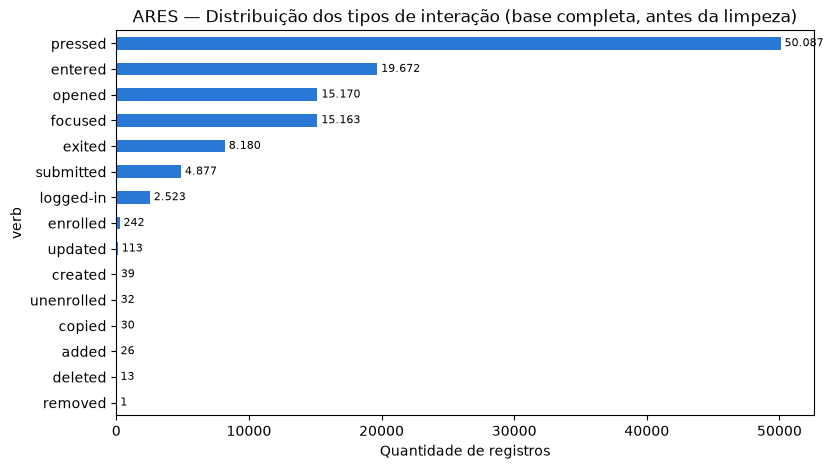

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
verbos.sort_values().plot(kind="barh", ax=ax, color="#2a78d6")
for i, v in enumerate(verbos.sort_values().values):
    ax.text(v, i, f" {v:,}".replace(",", "."), va="center", fontsize=8)
ax.set_title("ARES — Distribuição dos tipos de interação (base completa, antes da limpeza)")
ax.set_xlabel("Quantidade de registros")
ax.grid(axis="y", visible=False)
plt.show()

In [8]:
print("Objetos:")
display(xapi["object"].value_counts())
print("Exemplo do campo context (JSON):")
print(xapi["context"].iloc[2])

Objetos:


object
btn                 45333
dialog              22887
page                19672
txtView             15163
token                4369
assignment           3544
app                  2523
response             1345
filter                304
evaluation            288
klass                 274
word-explanation      205
text                   80
question               64
enter-key              42
construct              39
entity                 36
Name: count, dtype: int64

Exemplo do campo context (JSON):
{"extensions": {"http://mintly.kibi.group/contextExtension/fragment": "student_home.html", "http://mintly.kibi.group/contextExtension/dialogDescription": "tutorial modal"}}


O campo `context` é um JSON. Dele saem a **página** (`fragment`), a descrição do botão (`btnDescription`), do diálogo (`dialogDescription`) e o id da tarefa (`assignmentId`). Páginas mais frequentes:

In [9]:
EXT = "http://mintly.kibi.group/contextExtension/"
fragment = xapi["context"].apply(lambda c: json.loads(c).get("extensions", {}).get(EXT + "fragment"))
fragment.value_counts()

context
text.html                           72725
student_home.html                   11210
student_assignments.html            10536
pre_test.html                        4121
student_classes.html                 2980
login.html                           2804
post_test.html                       2380
background_questionnaire.html        1980
teacher_create_assignment.html       1142
mslq_questionnaire.html               815
motivation_questionnaire.html         723
teacher_edit_assignment.html          699
teacher_assignments.html              683
perception_questionnaire_en.html      624
engagement_questionnaire.html         481
consent_students.html                 456
teacher_manage_texts.html             333
admin_copy_assignment.html            273
teacher_home.html                     215
teacher_texts.html                    198
teacher_edit_text.html                185
user_profile.html                     113
teacher_grade_submission.html         110
teacher_browse_texts.html 

## 4. ARES — o instrumento de desempenho

O pré-teste e o pós-teste têm **12 itens**: Q1 a Q9 e Q10-1, Q10-2, Q10-3. A nota oficial vai de **0 a 11**. No notebook 02 mostramos que a nota oficial é a soma de acertos **sem a Q9**.

In [10]:
pre_resp = pd.read_excel(C.ARES_RAW / "pre_test_response.xlsx")
print("Itens do pré-teste:", sorted(pre_resp["prompt"].unique()))
print("Itens por aluno:", pre_resp.groupby("user_id").size().value_counts().to_dict())
print("Faixa da nota oficial (raw/pre_test_score):", pre_score_raw["score"].min(), "a", pre_score_raw["score"].max())

Itens do pré-teste: ['PreTestQ1', 'PreTestQ10-1', 'PreTestQ10-2', 'PreTestQ10-3', 'PreTestQ2', 'PreTestQ3', 'PreTestQ4', 'PreTestQ5', 'PreTestQ6', 'PreTestQ7', 'PreTestQ8', 'PreTestQ9']
Itens por aluno: {12: 210}
Faixa da nota oficial (raw/pre_test_score): 0 a 11


## 5. EdNet — onde estão os dados (§4.2)

O EdNet-KT3 tem **um CSV por estudante** (297.915 arquivos). O projeto aceita os dois formatos:

- **zip:** `EdNet-KT3.zip`
- **pasta descompactada:** `EdNet-KT3/` com os `u*.csv` dentro (direto ou numa subpasta `KT3/`)

O gabarito das questões fica em `EdNet-Contents` (`contents/questions.csv`).

**Onde colocar:** `data/raw/ednet/` dentro do projeto, ou uma pasta `Datasets/` (como em `Proj_mineracoa/Datasets/EdNet-KT3` e `Datasets/EdNet-Contents`), ou defina a variável de ambiente `EDNET_DIR`. A célula abaixo mostra onde o projeto procurou e o que encontrou.

In [11]:
print("Pastas procuradas, em ordem:")
for b in C._BASES:
    print("   ", b, "(existe)" if b.exists() else "")
print()
print("KT3 encontrado em:     ", C.EDNET_KT3)
print("Gabarito encontrado em:", C.EDNET_QUESTIONS if C.EDNET_QUESTIONS.is_file() else "NÃO ENCONTRADO")
print("EdNet bruto disponível:", C.EDNET_BRUTO_DISPONIVEL)
if not C.EDNET_BRUTO_DISPONIVEL:
    print("\n→ Sem o bruto, os notebooks usam data/processed/ednet_users.csv.gz (já processado).")

Pastas procuradas, em ordem:
    C:\Users\Usuário\Desktop\Datasets-Beready\Datasets-Beready\data\raw\ednet 
    C:\Users\Usuário\Desktop\Datasets-Beready\Datasets-Beready\Datasets 
    C:\Users\Usuário\Desktop\Datasets-Beready\Datasets 
    C:\Users\Usuário\Desktop\Datasets-Beready\Datasets-Beready-raw\ednet 
    C:\Users\Usuário\Datasets-Beready-raw\ednet 

KT3 encontrado em:      None
Gabarito encontrado em: NÃO ENCONTRADO
EdNet bruto disponível: False

→ Sem o bruto, os notebooks usam data/processed/ednet_users.csv.gz (já processado).


### Um arquivo de estudante, como ele vem

In [12]:
import ednet_01_extract as X

if C.EDNET_BRUTO_DISPONIVEL:
    arquivos = X.listar_arquivos()
    print(f"{len(arquivos):,} arquivos de estudantes".replace(",", "."))
    exemplo = X.ler_estudante("u5901")
    print("Linhas do estudante u5901:", len(exemplo))
    display(exemplo.head(15))
else:
    print("EdNet bruto não disponível nesta máquina; pulando a inspeção do arquivo bruto.")

EdNet bruto não disponível nesta máquina; pulando a inspeção do arquivo bruto.


### Dicionário do KT3

| Campo | Significado | Valores |
|---|---|---|
| `timestamp` | Momento da ação (ms desde 1970, UTC) | 1552470344907 |
| `action_type` | Ação | `enter`, `respond`, `submit`, `quit` |
| `item_id` | Item acessado. O prefixo indica o tipo | `b`=bloco de questões, `q`=questão, `e`=explicação, `l`=aula |
| `source` | Origem/contexto da atividade | `sprint`, `diagnosis`, `adaptive_offer`, `review_quiz`, `my_note`, `archive`, `tutor`, `review` |
| `user_answer` | Alternativa escolhida (só em `respond`) | a, b, c, d |
| `platform` | Dispositivo | `mobile`, `web` |

In [13]:
if C.EDNET_QUESTIONS.is_file():
    questoes = pd.read_csv(C.EDNET_QUESTIONS)
    print("Questões no gabarito:", len(questoes))
    display(questoes.head())
    if C.EDNET_LECTURES.is_file():
        print("Aulas:", len(pd.read_csv(C.EDNET_LECTURES)))
else:
    print("Gabarito (EdNet-Contents) não disponível nesta máquina.")

Gabarito (EdNet-Contents) não disponível nesta máquina.


### Volume total do EdNet

A leitura dos 89 milhões de linhas é feita no notebook 03, e o resultado fica registrado em `outputs/tables/ednet_qualidade.json`:

In [14]:
qual = json.loads((C.TAB / "ednet_qualidade.json").read_text(encoding="utf-8"))
print(f"Arquivos (estudantes): {qual['arquivos']:,}".replace(",", "."))
print(f"Linhas brutas:         {qual['linhas_brutas']:,}".replace(",", "."))
print(f"Linhas após limpeza:   {qual['linhas_limpas']:,}".replace(",", "."))

Arquivos (estudantes): 297.915
Linhas brutas:         89.270.654
Linhas após limpeza:   89.194.876


## Resumo do entendimento dos dados

- **ARES:** 116.168 eventos xAPI de 211 atores, com 15 verbos, entre 05/11/2024 e 05/02/2025. Pré e pós-teste de 12 itens com nota oficial de 0 a 11. As notas por aluno estão só em `raw/`.
- **EdNet-KT3:** 297.915 estudantes e 89,27 milhões de linhas, com ação, item, origem, resposta e plataforma. O gabarito permite corrigir cada resposta.

**Próximo:** `02_preparacao_ARES.ipynb`, com a limpeza, a sanitização e a validação do ARES.